# 12 · Stage 4: LTspice simulation of the $R_i$ staircase

**Purpose.** Simulates the configuration-B protocol in LTspice, step for step as the Arduino sketch drives it, at any list of step times, saves each run in the same two-column format as the bench recordings, and analyses the runs with the bench pipeline of notebook 10. It answers: does the simulated circuit tip too, and at what rate?

**In the report.** Chapter 7, Sec. 7.6: the simulated cycle map (Fig. 7.3b), the simulated points of the tipping diagram (Fig. 7.4), the mixed run at 12 ms and Eq. (7.5).

## Theory and protocol

Netlist: LM741 on ±15 V, $R_F = 90\,\mathrm{k\Omega}$, Wien arms $R = 2.17\,\mathrm{k\Omega}$, $C = 1\,\mu\mathrm{F}$, and $R_i$ a behavioural resistor `R = 1k*V(rctl)` driven by a piecewise-linear control voltage (volts = kΩ). A random voltage `NOISE_V*white(5e2*time + nseed)` (about 1 mV peak to peak) in series with $R_i$ seeds the oscillation. With identical arms $G_c = 3$ exactly, so thirteen staircase positions lie above threshold instead of seven on the bench (notebook 11), and the circuit should tolerate faster sweeps.

Timeline (as `Ri_sweep_staircase.ino`): 2 s settle at tap 0, a 50 ms trigger pulse, then 32 decrements (a hold, since the wiper is already at tap 0), 32 increments, 32 decrements, and so on, one change per step time $\tau$. Each saved file starts at the trigger's rising edge and lasts 60 s.

## Method

1. Build the list of tap changes of the configuration-B loop and write it as a PWL file (10 µs per transition).
2. Write the netlist, set the PWL file and the parameters with `PyLTSpice`, run LTspice (retry once with the gear integration method if a run fails).
3. Read the binary `.raw` file, check that $R_i$ followed `V(rctl)`, crop at the trigger's rising edge, resample to 0.3 ms and save as `time_series_sim_<delay>a.csv` (two columns, no header).
4. Analyse with the notebook-10 pipeline, with the exact step time ($\tau$ = delay) instead of a measured one.

## Requirements

LTspice 24+, `PyLTSpice`/`spicelib` and the TI LM741 model `lm741.lib` for the simulation cells; `numpy`, `pandas`, `scipy`, `matplotlib` for the analysis. With `RUN_SIMULATION = False` (default) only the analysis runs, on the included samples.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
RUN_SIMULATION = False
LTSPICE_EXE  = r"C:\Program Files\LTspice.exe"
LM741_LIB    = "lm741.lib"                    # path to the TI LM741 model
SIM_FOLDER   = "../data/stage4/simulation"   # simulated runs (sample: 15 ms and 10 ms); new runs are written here
SIM_WORK     = "outputs/12_stage4_sim/sim_work"
SIM_PATTERN  = "time_series_sim_*a.csv"
SIM_DELAYS_MS = [10, 12, 15, 18, 20, 22, 25, 27, 30, 32, 37, 38, 40, 41, 42, 43, 45, 50, 52, 53, 54, 55, 56,
                 58, 60, 65, 66, 67, 70, 75, 100]    # step times simulated for the report (31)
FULL_RESULTS = "../data/stage4/results"       # run and cycle tables of all 31 simulated runs, or None
OUT_DIR      = "outputs/12_stage4_sim"

T_SETTLE = 2.0; RECORD_S = 60.0; STEP_EDGE = 10e-6; MAXSTEP = 1e-4; DT_OUT = 0.3e-3
NOISE_V = 1e-3; SIM_TIMEOUT = 6 * 3600; RETRY_WITH_GEAR = True; SKIP_EXISTING = True
# configuration B and analysis settings (as notebook 10)
R_F = 90e3; RI_0 = 41e3; DELTA_RI = 10e3; N_STEPS = 31; STEPS_PER_HALF = 32; PRE_HOLD_STEPS = 32
TRIG_WIDTH = 0.050; R_WIEN, C_WIEN = 2.17e3, 1e-6
ENV_WINDOW = 0.03; FULL_ON = 0.90; LOW, HIGH = 0.10, 0.90; TRACK_FRACTION = 0.8

## 1. Analysis helpers (same as notebook 10)

In [2]:
import os, re, glob, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter1d
os.makedirs(OUT_DIR, exist_ok=True)
SIM_FOLDER, SIM_WORK = os.path.abspath(SIM_FOLDER), os.path.abspath(SIM_WORK)
OMEGA0 = 1 / (R_WIEN * C_WIEN)
STEP_RI = DELTA_RI / N_STEPS
TOP_TAP = min(STEPS_PER_HALF, N_STEPS)

def delay_of(path):
    m = re.search(r"_(\d+(?:\.\d+)?)a\.csv$", os.path.basename(path))
    return float(m.group(1)) if m else np.nan


def load_run(path):
    """Two columns, no header: time (s), Vout (V). Resampled onto a uniform time grid."""
    d = pd.read_csv(path, header=None).apply(pd.to_numeric, errors="coerce").dropna()
    t, v = d.iloc[:, 0].to_numpy(float), d.iloc[:, 1].to_numpy(float)
    t, idx = np.unique(t, return_index=True)
    v = v[idx]
    dt = float(np.median(np.diff(t)))
    grid = np.arange(t[0], t[-1], dt)
    return grid, np.interp(grid, t, v), dt


def runmax(x, n, side):
    """Running max: side='back' -> window [i-n+1, i] (exact on rising edges), 'fwd' -> [i, i+n-1] (falling edges)."""
    o = (n - 1) // 2 if side == "back" else -(n // 2)
    return maximum_filter1d(x, n, origin=o, mode="nearest")


def envelope(v, dt, window=None):
    n = max(3, int(round((window or ENV_WINDOW) / dt)))
    pos = np.clip(v, 0, None)
    return np.minimum(runmax(pos, n, "back"), runmax(pos, n, "fwd"))


def first_cross_up(t, y, level, lo, hi):
    """First upward crossing of `level` in [lo, hi), interpolated; NaN if y starts above level or never crosses."""
    if hi - lo < 2 or y[lo] >= level:
        return np.nan
    idx = np.where(y[lo:hi] >= level)[0]
    if len(idx) == 0:
        return np.nan
    i = lo + idx[0]
    return t[i - 1] + (level - y[i - 1]) * (t[i] - t[i - 1]) / (y[i] - y[i - 1])


def last_cross_down(t, y, level, lo, hi):
    """Last downward crossing of `level` in [lo, hi); NaN if y does not end below level."""
    if hi - lo < 2 or y[hi - 1] >= level:
        return np.nan
    idx = np.where(y[lo:hi] >= level)[0]
    if len(idx) == 0:
        return np.nan
    j = lo + idx[-1]
    return t[j] + (y[j] - level) * (t[j + 1] - t[j]) / (y[j] - y[j + 1])


# ---------------- pot model: exactly the Arduino loop ----------------
def sweep_x(t, tau):
    """Steps since the first increment (negative during the initial hold) and position u in the 64-step cycle."""
    t1 = TRIG_WIDTH + PRE_HOLD_STEPS * tau
    x = (np.asarray(t, float) - t1) / tau
    return x, np.mod(x, 2 * STEPS_PER_HALF)


def k_lin(t, tau):
    """Tap number as a straight line through the middle of each step (flat on the holds); 0 before the sweep."""
    x, u = sweep_x(t, tau)
    k = np.clip(np.minimum(u + 0.5, TOP_TAP + STEPS_PER_HALF - 0.5 - u), 0, TOP_TAP)
    return np.where(x < 0, 0.0, k)


def Ri_of_t(t, tau):
    return RI_0 + STEP_RI * k_lin(t, tau)


def G_of_Ri(Ri):
    return 1 + R_F / np.asarray(Ri, float)


def branch_of(t, tau):
    """Part of the sweep at time t (as text)."""
    x, u = sweep_x(np.atleast_1d(t), tau)
    out = np.empty(x.shape, dtype=object)
    for i, (xi, ui) in enumerate(zip(x, u)):
        if xi < 0:
            out[i] = "initial hold (G highest)"
        elif ui < TOP_TAP - 0.5:
            out[i] = "Ri rising (G falling)"
        elif ui < STEPS_PER_HALF - 0.5:
            out[i] = "top hold (G lowest)"
        elif ui < TOP_TAP + STEPS_PER_HALF - 0.5:
            out[i] = "Ri falling (G rising)"
        else:
            out[i] = "bottom hold (G highest)"
    return out

def analyse_run(path, tau_override=None):
    D = delay_of(path)
    t, v, dt = load_run(path)
    tau_nom = D / 1000.0

    # baseline (median of the quiet parts), envelope, rail = level of the run's own initial oscillation
    raw_env = envelope(np.abs(v), dt)
    quiet = raw_env < 0.1 * np.percentile(raw_env, 99)
    if quiet.sum() > 100:
        v = v - np.median(v[quiet])
    env = envelope(v, dt)
    t1_nom = TRIG_WIDTH + PRE_HOLD_STEPS * tau_nom
    init = (t > 0.1) & (t < max(t1_nom - 0.05, 0.2))
    V_rail = float(np.median(env[init])) if init.sum() > 10 else float(np.percentile(env, 99.5))

    def per_cycle(tau):
        t1 = TRIG_WIDTH + PRE_HOLD_STEPS * tau
        rows, n = [], 1
        while True:
            c = t1 + (2 * STEPS_PER_HALF * n - 1) * tau          # middle of the n-th bottom hold (G highest)
            a, b = c - STEPS_PER_HALF * tau, c + STEPS_PER_HALF * tau
            if b > t[-1]:
                break
            lo, hi = np.searchsorted(t, a), np.searchsorted(t, b)
            pk = env[lo:hi].max()
            r = dict(cycle=n, A_peak=pk / V_rail, V_peak=pk, t_start=t[lo], t_end=t[hi - 1],
                     full_on=bool(pk >= FULL_ON * V_rail))
            r["t_on50"] = first_cross_up(t, env, 0.5 * V_rail, lo, hi)
            r["t_on90"] = first_cross_up(t, env, HIGH * V_rail, lo, hi)
            r["t_off50"] = last_cross_down(t, env, 0.5 * V_rail, lo, hi) if np.isfinite(r["t_on50"]) else np.nan
            r["t_off10"] = last_cross_down(t, env, LOW * V_rail, lo, hi) if np.isfinite(r["t_on90"]) else np.nan
            rows.append(r)
            n += 1
        cols = ["cycle", "A_peak", "V_peak", "t_start", "t_end", "full_on", "t_on50", "t_on90", "t_off50", "t_off10"]
        return t1, pd.DataFrame(rows, columns=cols)

    # pass 1 with the nominal delay; if the run keeps switching on, measure tau from the burst onsets
    t1, cyc = per_cycle(tau_nom)
    tau, tau_src = tau_nom, "nominal (file name)"
    if tau_override is not None:
        tau, tau_src = tau_override, "given"
    else:
        ok = cyc.t_on50.notna()
        if ok.sum() >= 3:
            T_meas = np.polyfit(cyc.cycle[ok].astype(float), cyc.t_on50[ok].astype(float), 1)[0]
            if abs(T_meas / (2 * STEPS_PER_HALF * tau_nom) - 1) < 0.05:
                tau, tau_src = T_meas / (2 * STEPS_PER_HALF), "measured (burst onsets)"
    t1, cyc = per_cycle(tau)

    # first switch-off of the initial oscillation
    first_hi = np.searchsorted(t, t1 + (STEPS_PER_HALF - 1) * tau)
    t_off10_1 = last_cross_down(t, env, LOW * V_rail, 0, first_hi)
    t_off50_1 = last_cross_down(t, env, 0.5 * V_rail, 0, first_hi)

    for col in ["t_on50", "t_on90", "t_off50", "t_off10"]:
        key = col[2:]
        x = cyc[col].to_numpy(float)
        cyc["Ri_" + key] = np.where(np.isfinite(x), Ri_of_t(np.nan_to_num(x), tau), np.nan)
        cyc["G_" + key] = G_of_Ri(cyc["Ri_" + key])
        cyc["branch_" + key] = [branch_of(xx, tau)[0] if np.isfinite(xx) else "" for xx in x]

    lam = STEP_RI / tau
    Ri1 = float(Ri_of_t(t_off10_1, tau)) if np.isfinite(t_off10_1) else np.nan
    info = dict(file=os.path.basename(path), delay_ms=D, tau_ms=tau * 1e3, tau_source=tau_src,
                lambda_ohm_s=lam, dt_ms=dt * 1e3, duration_s=t[-1] - t[0], V_rail=V_rail, n_cycles=len(cyc),
                t_first_off10=t_off10_1, t_first_off50=t_off50_1,
                Ri_first_off10=Ri1, G_first_off10=float(G_of_Ri(Ri1)) if np.isfinite(Ri1) else np.nan)
    return info, cyc, (t, v, env)


def classify(cyc):
    """Long-time state from all complete cycles after the first switch-off."""
    if len(cyc) == 0:
        return "no complete cycle", np.nan
    f = float(cyc.full_on.mean())
    if f >= TRACK_FRACTION:
        return "switches back on every cycle", f
    if f == 0:
        return "stays off (never switches back on)", f
    return "mixed", f


def analyse_folder(folder, pattern, tau_overrides=None):
    files = sorted(glob.glob(os.path.join(folder, pattern)), key=delay_of)
    if not files:
        raise FileNotFoundError(f"No files matching {pattern!r} in {os.path.abspath(folder)!r}")
    infos, cycs, traces = [], {}, {}
    for f in files:
        D = delay_of(f)
        info, cyc, tr = analyse_run(f, tau_override=(tau_overrides or {}).get(D))
        state, frac = classify(cyc)
        info.update(state=state, frac_full_on=frac,
                    A_peak_median=float(cyc.A_peak.median()) if len(cyc) else np.nan,
                    A_peak_min=float(cyc.A_peak.min()) if len(cyc) else np.nan,
                    A_peak_max=float(cyc.A_peak.max()) if len(cyc) else np.nan)
        infos.append(info); cycs[D] = cyc; traces[D] = tr
    runs = pd.DataFrame(infos).sort_values("lambda_ohm_s").reset_index(drop=True)
    return runs, cycs, traces

## 2. Netlist, staircase and LTspice helpers

In [3]:
NETLIST = r"""* Wien bridge, R_i swept by a staircase (generated by the notebook)
XU1 N001 inv V+ V- Vout LM741
V1 V+ 0 15
V2 0 V- 15
Vr rctl 0 PWL(0 41)
Vtrig trig 0 PULSE(0 5 {T_SETTLE} 1u 1u 50m 1e6 1)
R1 Vout inv 90k
R2 inv a R=1k*V(rctl)
R3 N002 N001 2.17k
R4 0 N001 2.17k
C1 N001 0 1u
C2 Vout N002 1u
B1 a 0 V={NOISE_V}*white(5e2*time+{{nseed}})
.inc {LM741_LIB}
.param Tstop=10 maxstep=0.1m nseed=0
.tran 0 {{Tstop}} 0 {{maxstep}}
.options plotwinsize=0
.save V(vout) V(trig) V(rctl) V(inv) V(a) I(R2)
.end
"""


def ri_tap_events(tau, t_stop):
    """(time, tap) after every pot change for the configuration-B sketch: 32 decrements (no change at tap 0), then up/down."""
    t_s = T_SETTLE + TRIG_WIDTH                       # sweep starts at the trigger's falling edge
    tap, ev, j = 0, [], 0
    while True:
        t = t_s + j * tau
        if t > t_stop:
            break
        phase = (j // STEPS_PER_HALF) % 2             # 0: decrease block, 1: increase block
        new = max(tap - 1, 0) if phase == 0 else min(tap + 1, TOP_TAP)
        if new != tap:
            ev.append((t, tap, new)); tap = new
        j += 1
    return ev


def write_pwl(points, path):
    times = np.array([p[0] for p in points])
    if not np.all(np.diff(times) > 0):
        raise ValueError("PWL times not strictly increasing")
    with open(path, "w") as fh:
        for t, val in points:
            fh.write(f"{t:.9f} {val:.9f}\n")


def staircase_pwl(tau, t_stop):
    kohm = lambda tap: (RI_0 + STEP_RI * tap) / 1e3
    pts = [(0.0, kohm(0))]
    for t, old, new in ri_tap_events(tau, t_stop):
        pts += [(t, kohm(old)), (t + STEP_EDGE, kohm(new))]
    pts.append((max(pts[-1][0], t_stop) + 1.0, pts[-1][1]))
    return pts


def read_ltspice_raw(path):
    """Binary LTspice raw reader (UTF-16 header; time float64, other traces float32 unless 'double'; FastAccess ok)."""
    size = os.path.getsize(path)
    with open(path, "rb") as fh:
        head = fh.read(min(size, 1 << 20))
    for enc, marker in (("utf-16-le", "Binary:\n".encode("utf-16-le")), ("latin-1", b"Binary:\n")):
        pos = head.find(marker)
        if pos >= 0:
            header, offset = head[:pos].decode(enc, errors="replace"), pos + len(marker)
            break
    else:
        raise ValueError(f"{path}: no 'Binary:' section")
    info, names, in_vars = {}, [], False
    for line in header.splitlines():
        if in_vars:
            p = line.split()
            if len(p) >= 2 and p[0].isdigit():
                names.append(p[1])
            continue
        if line.startswith("Variables:"):
            in_vars = True
        elif ":" in line:
            k, v = line.split(":", 1); info[k.strip()] = v.strip()
    flags = info.get("Flags", "").lower()
    if not names or names[0].lower() != "time":
        raise ValueError(f"{path}: no time axis (plot '{info.get('Plotname')}')")
    nv = len(names); wv = 8 if "double" in flags else 4
    n = (size - offset) // (8 + (nv - 1) * wv)
    cols = {}
    if "fastaccess" in flags:
        n_hdr = int(info.get("No. Points", n)); n = min(n, n_hdr); pos = offset
        for k, nm in enumerate(names):
            w = 8 if k == 0 else wv
            cols[nm] = np.fromfile(path, dtype="<f8" if w == 8 else "<f4", count=n, offset=pos).astype(float)
            pos += w * n_hdr
    else:
        dt_ = np.dtype([("v", "<f8", (nv,))]) if wv == 8 else np.dtype([("t", "<f8"), ("v", "<f4", (nv - 1,))])
        rec = np.memmap(path, dtype=dt_, mode="r", offset=offset, shape=(n,))
        if wv == 8:
            arr = np.array(rec["v"], float); cols = {nm: arr[:, k].copy() for k, nm in enumerate(names)}
        else:
            cols[names[0]] = np.array(rec["t"], float); vv = np.array(rec["v"], float)
            for k, nm in enumerate(names[1:]):
                cols[nm] = vv[:, k].copy()
        del rec
    return {k.lower(): v for k, v in cols.items()}


def run_ltspice_case(stem, pwl_points, t_stop, idx, gear=False):
    from PyLTSpice import SimRunner, SpiceEditor
    from spicelib.simulators.ltspice_simulator import LTspice
    LTspice.create_from(LTSPICE_EXE)
    os.makedirs(SIM_WORK, exist_ok=True)
    base = os.path.join(SIM_WORK, "base_Ri.net")
    with open(base, "w", encoding="ascii") as fh:
        fh.write(NETLIST.format(T_SETTLE=T_SETTLE, NOISE_V=NOISE_V, LM741_LIB=LM741_LIB))
    pwl_path = os.path.join(SIM_WORK, stem + ".pwl")
    write_pwl(pwl_points, pwl_path)
    ed = SpiceEditor(base)
    ed.set_component_value("Vr", f'PWL file="{pwl_path}"')
    ed.set_parameters(Tstop=f"{t_stop:.9g}", maxstep=f"{MAXSTEP:.9g}", nseed=f"{1000 * (idx + 1)}")
    if gear:
        ed.add_instruction(".options method=gear cshunt=1e-15")
    run = SimRunner(output_folder=SIM_WORK, timeout=SIM_TIMEOUT)
    run.run(ed, run_filename=stem + ".net", timeout=SIM_TIMEOUT)
    run.wait_completion()
    raw = os.path.join(SIM_WORK, stem + ".raw")
    if not os.path.exists(raw):
        return None, "no raw file"
    cols = read_ltspice_raw(raw)
    t = np.abs(cols["time"])
    if t[-1] < 0.999 * t_stop:
        return None, f"stopped early at {t[-1]:.3f} s"
    return cols, "ok"


def rf_check(cols):
    i = cols.get("i(r2)"); va = cols.get("v(a)"); vi = cols.get("v(inv)")
    if i is None or va is None or vi is None:
        return np.nan
    ok = np.abs(i) > 1e-7
    return float(np.median(np.abs(np.abs((vi[ok] - va[ok]) / i[ok]) / (1e3 * cols["v(rctl)"][ok]) - 1)))


def save_like_scope(cols, path, t_from):
    """Crop at the trigger's rising edge, shift to t = 0, resample, save as 2 columns without header."""
    t = np.abs(cols["time"]); t, k = np.unique(t, return_index=True)
    v = cols["v(vout)"][k]
    grid = np.arange(t_from, t[-1], DT_OUT)
    out = pd.DataFrame({0: grid - t_from, 1: np.interp(grid, t, v)})
    out.to_csv(path, header=False, index=False, float_format="%.6f")
    return len(out)


def run_ri_simulations(delays_ms):
    os.makedirs(SIM_FOLDER, exist_ok=True)
    log = []
    for idx, D in enumerate(delays_ms):
        out_csv = os.path.join(SIM_FOLDER, f"time_series_sim_{D:g}a.csv")
        if SKIP_EXISTING and os.path.exists(out_csv):
            print(f"tau = {D} ms: exists, skipped"); continue
        tau = D / 1000.0
        t_stop = T_SETTLE + RECORD_S
        pts = staircase_pwl(tau, t_stop)
        status, method = "not run", ""
        for gear in ([False, True] if RETRY_WITH_GEAR else [False]):
            method = "gear" if gear else "trap"
            t0 = __import__("time").time()
            try:
                cols, status = run_ltspice_case(f"sim_Ri_{D:g}" + ("_gear" if gear else ""), pts, t_stop, idx, gear)
            except Exception as err:
                cols, status = None, f"error: {err}"
            print(f"tau = {D} ms [{method}] {status} ({(__import__('time').time() - t0) / 60:.1f} min)")
            if cols is not None:
                break
        if cols is not None:
            rc = rf_check(cols)
            n = save_like_scope(cols, out_csv, T_SETTLE)
            print(f"   saved {out_csv} ({n} rows), R_i check (median rel. error) = {rc:.1e}")
        log.append(dict(delay_ms=D, status=status, method=method))
    print(pd.DataFrame(log).to_string(index=False))

## 3. Run the simulations (needs LTspice)

In [4]:
if RUN_SIMULATION:
    run_ri_simulations(SIM_DELAYS_MS)
else:
    print("RUN_SIMULATION = False: no LTspice runs.")

RUN_SIMULATION = False: no LTspice runs.


## 4. Analyse the simulated runs in `SIM_FOLDER`

In [5]:
files = glob.glob(os.path.join(SIM_FOLDER, SIM_PATTERN))
runs, cycs, traces = analyse_folder(SIM_FOLDER, SIM_PATTERN, tau_overrides={delay_of(f): delay_of(f) / 1000.0 for f in files})
cyc_table = pd.concat([c.assign(delay_ms=d) for d, c in cycs.items()], ignore_index=True)
runs.to_csv(os.path.join(OUT_DIR, "runs.csv"), index=False); cyc_table.to_csv(os.path.join(OUT_DIR, "cycles.csv"), index=False)
print(runs[["delay_ms", "lambda_ohm_s", "n_cycles", "state", "frac_full_on", "A_peak_min", "A_peak_max"]].round(3).to_string(index=False))

 delay_ms  lambda_ohm_s  n_cycles                              state  frac_full_on  A_peak_min  A_peak_max
     15.0     21505.376        61       switches back on every cycle         0.967       0.624       1.000
     10.0     32258.065        92 stays off (never switches back on)         0.000       0.019       0.568


## 5. The simulated tipping (all 31 runs) and a parameter-free estimate of the critical rate

re-ignites every cycle up to 21.5 kOhm/s, stays off from 32.3 kOhm/s
mixed run: tau = 12 ms (26.9 kOhm/s): 31 of 77 cycles re-ignite
13 positions above G_c = 3; effective noise floor 14.9 mV -> estimated lambda_c = 27.7 kOhm/s


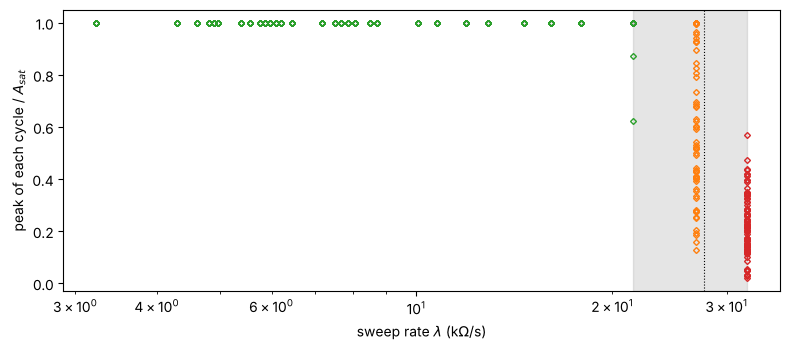

In [6]:
R = pd.read_csv(os.path.join(FULL_RESULTS, "sim_runs.csv")) if FULL_RESULTS else runs
Cy = pd.read_csv(os.path.join(FULL_RESULTS, "sim_cycles.csv")) if FULL_RESULTS else cyc_table
ON, OFF = "switches back on every cycle", "stays off (never switches back on)"
lam_on, lam_off = R[R.state == ON].lambda_ohm_s.max(), R[R.state == OFF].lambda_ohm_s.min()
mixed = R[R.state == "mixed"]
print(f"re-ignites every cycle up to {lam_on/1e3:.1f} kOhm/s, stays off from {lam_off/1e3:.1f} kOhm/s")
for _, r in mixed.iterrows():
    c = Cy[Cy.delay_ms == r.delay_ms]
    print(f"mixed run: tau = {r.delay_ms:.0f} ms ({r.lambda_ohm_s/1e3:.1f} kOhm/s): {int((c.A_peak >= FULL_ON).sum())} of {len(c)} cycles re-ignite")
# growth-budget estimate with the simulation's effective noise floor (Stage 3: Lambda_on = 6.7 -> delta ~ 15 mV)
taps = np.arange(N_STEPS + 1); Gk = 1 + R_F / (RI_0 + STEP_RI * taps); S_plus = np.clip(Gk - 3.0, 0, None).sum()
delta_eff = 0.9 * 13.9 * np.exp(-6.73)
lam_c_est = OMEGA0 * STEP_RI * S_plus / np.log(13.9 / delta_eff)
print(f"{int((Gk > 3).sum())} positions above G_c = 3; effective noise floor {delta_eff*1e3:.1f} mV -> estimated lambda_c = {lam_c_est/1e3:.1f} kOhm/s")
COL = {ON: "tab:green", OFF: "tab:red", "mixed": "tab:orange"}
fig, ax = plt.subplots(figsize=(8, 3.6))
for _, r in R.iterrows():
    a = Cy[Cy.delay_ms == r.delay_ms].A_peak.to_numpy(); ax.plot(np.full(len(a), r.lambda_ohm_s / 1e3), a, "D", mfc="none", ms=3, color=COL.get(r.state, "gray"))
ax.axvspan(lam_on / 1e3, lam_off / 1e3, color="gray", alpha=0.2); ax.axvline(lam_c_est / 1e3, color="k", ls=":", lw=0.8)
ax.set_xscale("log"); ax.set_xlabel(r"sweep rate $\lambda$ (k$\Omega$/s)"); ax.set_ylabel(r"peak of each cycle / $A_{sat}$")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "sim_tipping.png"), dpi=150); plt.show()

## Check against the report

In [7]:
checks = {
    "31 simulated runs": len(R) == 31,
    "re-ignites every cycle from 100 down to 15 ms; stays off at 10 ms": R[R.delay_ms >= 15].state.eq(ON).all() and R[R.delay_ms == 10].state.iloc[0] == OFF,
    "12 ms mixed: 31 of 77 cycles (40 %) re-ignite": len(mixed) == 1 and mixed.delay_ms.iloc[0] == 12
        and int((Cy[Cy.delay_ms == 12].A_peak >= FULL_ON).sum()) == 31 and len(Cy[Cy.delay_ms == 12]) == 77,
    "Eq. 7.5: 21.5 < lambda_c(sim) < 32.3 kOhm/s": round(lam_on / 1e3, 1) == 21.5 and round(lam_off / 1e3, 1) == 32.3,
    "thirteen positions above threshold; estimate about 27.6 kOhm/s": int((Gk > 3).sum()) == 13 and abs(lam_c_est - 27600) < 150,
    "at 15 ms all but two of 61 cycles re-ignite": int((Cy[Cy.delay_ms == 15].A_peak >= FULL_ON).sum()) == 59 and len(Cy[Cy.delay_ms == 15]) == 61,
}
for k, v in checks.items(): print(("PASS " if v else "FAIL ") + k)
for _, r in runs.iterrows():
    f = R[R.delay_ms == r.delay_ms].iloc[0]
    print(("PASS" if f.state == r.state and int(f.n_cycles) == int(r.n_cycles) else "FAIL") + f" sample run tau = {r.delay_ms:.0f} ms reproduces its row of the full table")

PASS 31 simulated runs
PASS re-ignites every cycle from 100 down to 15 ms; stays off at 10 ms
PASS 12 ms mixed: 31 of 77 cycles (40 %) re-ignite
PASS Eq. 7.5: 21.5 < lambda_c(sim) < 32.3 kOhm/s
PASS thirteen positions above threshold; estimate about 27.6 kOhm/s
PASS at 15 ms all but two of 61 cycles re-ignite
PASS sample run tau = 15 ms reproduces its row of the full table
PASS sample run tau = 10 ms reproduces its row of the full table


## Using your own circuit

Edit `NETLIST` (keep the node names `vout`, `trig`, `rctl`, `inv`, `a`), the configuration values and `SIM_DELAYS_MS`. The analysis reads any two-column files named `..._<delay>a.csv`, so bench and simulated runs can be compared directly.